<a href="https://colab.research.google.com/github/swatijaincts/GENAI-Course/blob/Colab-link/Great_Learning_Attention_Visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#install library dependencies
!pip install -q gensim sentence-transformers scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 39.8 MB/s eta 0:00:00


In [ ]:
#import the installed libraries into current program
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from gensim.downloader import load
from sentence_transformers import SentenceTransformer

from sklearn.decomposition import PCA
import torch

from transformers import AutoTokenizer, AutoModel
from transformers import BertModel


In [ ]:
#Downloading the Enbedding models
print("Loading Word2Vec...")
word2vec = load("word2vec-google-news-300")
print("Done")

print("Loading GloVe...")
glove = load("glove-wiki-gigaword-300")
print("Done")

print("Loading Transformer...")
bert = SentenceTransformer("all-MiniLM-L6-v2")
print("Done")

Loading Word2Vec...
[==================================================] 100.0% 1662.8/1662.8MB downloaded
Done
Loading GloVe...
[==================================================] 100.0% 376.1/376.1MB downloaded
Done
Loading Transformer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Done


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
save_path = "/content/drive/MyDrive/word2vec-google-news-300.model"

word2vec.save(save_path)

In [ ]:
#define the tokenizer for contextual embedding
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)



model = AutoModel.from_pretrained("bert-base-uncased")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
#define a list  of words for visualization
electronics = [

    "iphone",

    "computer",

    "software",

    "google",

    "microsoft",

    "technology",

    "internet",

    "keyboard",

    "processor",

    "monitor",

]

fruits = [

    "banana",

    "orange",

    "mango",

    "grape",

    "pear",

    "fruit",

    "pineapple",

    "peach",

]

In [ ]:
def plot_embedding(model,title):
    #create list of words
    words = electronics + fruits + ["apple"]

    #convert words into vector embeddings
    vectors = np.array(
        [model[w] for w in words]
    )

    #compress  the vectors into 2D
    coords = PCA(
        n_components=2
    ).fit_transform(vectors)

    plt.figure(figsize=(8,7))

    for word,(x,y) in zip(words,coords):

        if word in electronics:

            color="blue"

        elif word in fruits:

            color="green"

        else:

            color="red"

        plt.scatter(
            x,
            y,
            c=color,
            s=120
        )

        plt.text(
            x+.02,
            y+.02,
            word,
            fontsize=10
        )

    plt.title(title)

    plt.grid(True)

    plt.show()

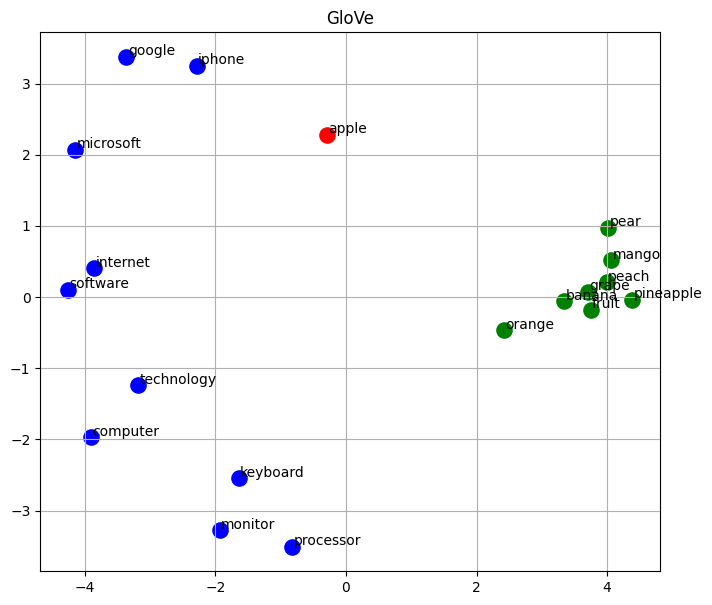

In [ ]:
#Glove embedding
plot_embedding(
    glove,
    "GloVe"
)

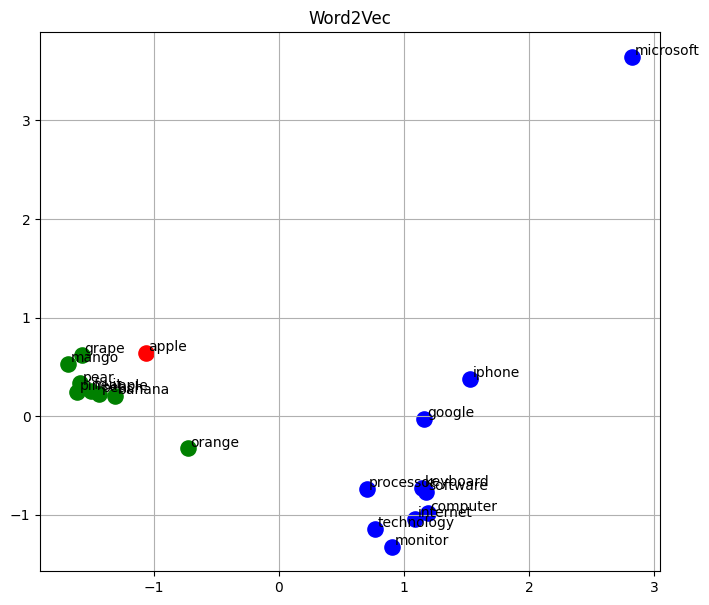

In [ ]:
#word2Vec visualisation
plot_embedding(
    word2vec,
    "Word2Vec"
)

In [ ]:
#Example vector
print(word2vec["apple"][:10])

[-0.06445312 -0.16015625 -0.01208496  0.13476562 -0.22949219  0.16210938
  0.3046875  -0.1796875  -0.12109375  0.25390625]


In [ ]:
def get_contextual_embedding(sentence, target_word):

    #convert input sentence into tokens and coressponding Vocab IDs
    inputs = tokenizer(sentence, return_tensors="pt")

    #Obataining Contextual Embedding through BERT model
    with torch.no_grad():
        outputs = bert(**inputs)

    #Converting Ids back to tokens(words)
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])


    #converting the word to lower case
    target_word = target_word.lower()
    for i, tok in enumerate(tokens):
        if tok == target_word:
            idx = i
            break
    else:
        raise ValueError(f"{target_word} not found.")

    return outputs.last_hidden_state[0, idx].cpu().numpy()

In [ ]:
electronics_sentences = {
    "iphone": "The iPhone was released yesterday.",
    "computer": "The computer is very fast.",
    "software": "The software needs an update.",
    "google": "Google announced a new feature.",
    "microsoft": "Microsoft is great fruit ",
    "technology": "Technology changes rapidly.",
    "internet": "The internet is down."
}

fruit_sentences = {
    "banana": "I ate a banana.",
    "orange": "The orange is sweet.",
    "mango": "The mango is ripe.",
    "pear": "The pear tastes good.",
    "fruit": "Fruit is healthy.",

}

In [ ]:
electronics_embeddings = []


#obtaining the Contextual embedding of all selected words
for word, sent in electronics_sentences.items():
    electronics_embeddings.append(
        get_contextual_embedding(sent, word)
    )

fruit_embeddings = []
#obtaining the Contextual embedding of all selected words
for word, sent in fruit_sentences.items():
    fruit_embeddings.append(
        get_contextual_embedding(sent, word)
    )

apple_company = get_contextual_embedding(
    "Apple released a new iPhone.",
    "apple"
)

apple_fruit = get_contextual_embedding(
    "Apple is excellent",
    "apple"
)

In [ ]:
from sklearn.decomposition import PCA

all_vectors = (
    electronics_embeddings +
    fruit_embeddings +
    [apple_company, apple_fruit]
)
#creating labels for plotting
labels = (
    list(electronics_sentences.keys()) +
    list(fruit_sentences.keys()) +
    ["Apple (Company)", "Apple (Fruit)"]
)

coords = PCA(n_components=2).fit_transform(all_vectors)

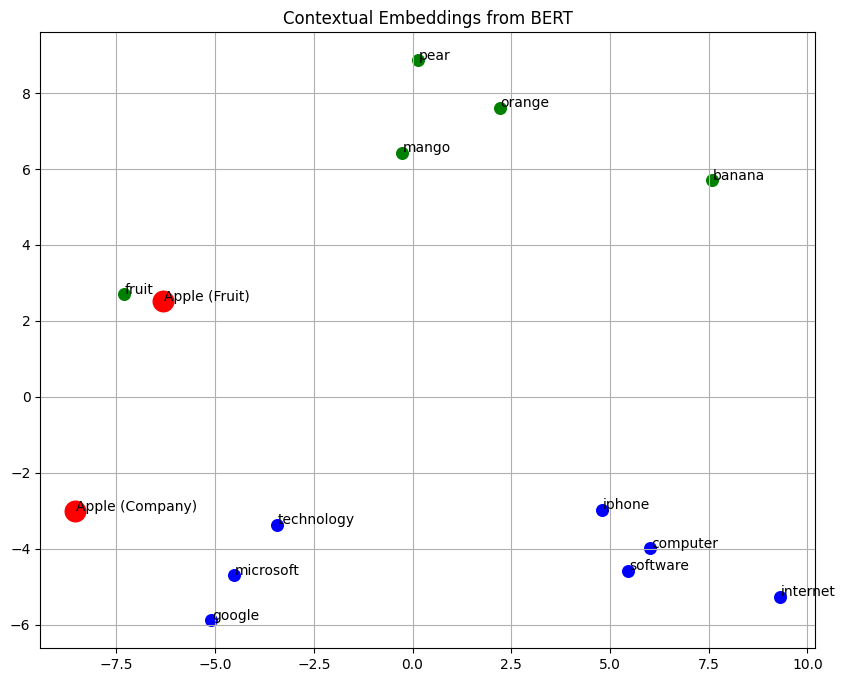

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for (x, y), label in zip(coords, labels):

    if label in electronics_sentences:
        color = "blue"
        size = 70

    elif label in fruit_sentences:
        color = "green"
        size = 70

    else:
        color = "red"
        size = 220

    plt.scatter(x, y, s=size, color=color)

    plt.text(x + 0.02, y + 0.02, label, fontsize=10)

plt.title("Contextual Embeddings from BERT")
plt.grid(True)
plt.show()